# Nvidia: when analysts cut in a wave, were they right?
### Analyst target-price cuts, downgrades and what the stock did next (2017–2026)

On 12 November 2026 Nvidia received 12 target-price cuts and 8 downgrades in a single day, after a ~30% fall from its October 2026 high.
This notebook asks a simple question with Nvidia's own history: **after past waves of analyst cuts, did the stock keep falling (analysts were right) or recover (the selling was overdone)?**

**Structure**
1. Data: every rating and price-target change on NVDA since 2017 (Yahoo Finance) and daily prices
2. Cleaning: split adjustment and target revisions
3. Cut waves: identifying past episodes
4. What happened next: returns at 1, 3, 6 and 12 months, extra downside, recovery time, target accuracy
5. A second lens: every drawdown of more than 25%
6. Charts
7. Findings and limitations

## 1. Data

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

TITOLO = "NVDA"
INIZIO = "2017-01-01"
FINE = "2026-11-13"        # data fissa: i risultati restano replicabili

# Ogni cambio di rating e di target price, con data, broker, target precedente e nuovo
ud = yf.Ticker(TITOLO).upgrades_downgrades.reset_index()
ud = ud[ud["GradeDate"] < FINE]

# Prezzi giornalieri aggiustati di Nvidia e S&P 500
px = yf.download([TITOLO, "^GSPC"], start=INIZIO, end=FINE, auto_adjust=True, progress=False)["Close"]
px = px.rename(columns={"^GSPC": "SPX"})

print(ud.shape, ud["GradeDate"].min(), "->", ud["GradeDate"].max())
print(px.shape)

(1008, 8) 2017-08-14 15:25:37 -> 2026-11-12 18:17:25
(2480, 2)


## 2. Cleaning
- A target of 0 in Yahoo's data means "no target given" and is set to missing.
- Yahoo's prices are adjusted for Nvidia's 4-for-1 (July 2021) and 10-for-1 (June 2024) splits, but older targets are not. Targets before each split are divided by the split ratio so they are comparable with prices.
- Each target change is measured as new / previous target − 1.
- Each action is assigned to its trading day (or the next one, if it falls on a non-trading day).

In [2]:
ud["data"] = ud["GradeDate"].dt.normalize()
for c in ["currentPriceTarget", "priorPriceTarget"]:
    ud[c] = ud[c].replace(0, np.nan)            # 0 = target mancante

# Aggiustamento per gli split: /40 prima di luglio 2021, /10 fino a giugno 2024
fattore = np.where(ud["data"] < "2021-07-20", 40, np.where(ud["data"] < "2024-06-10", 10, 1))
ud["target_nuovo"] = ud["currentPriceTarget"] / fattore
ud["target_vecchio"] = ud["priorPriceTarget"] / fattore

# Revisione % del target ("Adjusts" = ricalcolo tecnico per lo split, escluso)
validi = ud["priceTargetAction"].isin(["Lowers", "Raises", "Maintains"])
ud["revisione"] = np.where(validi, ud["target_nuovo"] / ud["target_vecchio"] - 1, np.nan)

# Giorno di borsa di ogni azione
date_borsa = px.index
ud["giorno"] = [date_borsa[date_borsa >= d][0] if (date_borsa >= d).any() else pd.NaT for d in ud["data"]]

print(ud[["GradeDate", "Firm", "Action", "priceTargetAction", "target_vecchio", "target_nuovo", "revisione"]].head(12))

             GradeDate               Firm Action priceTargetAction  \
0  2026-11-12 18:17:25    Melius Research   down            Lowers   
1  2026-11-12 18:13:07        DA Davidson   main            Lowers   
2  2026-11-12 17:52:20       Craig-Hallum   down         Announces   
3  2026-11-12 17:46:29  B of A Securities   main            Lowers   
4  2026-11-12 16:53:12        BMO Capital   main            Lowers   
5  2026-11-12 16:51:26              Baird   reit         Maintains   
6  2026-11-12 16:47:08      Goldman Sachs   main            Lowers   
7  2026-11-12 15:56:51          Citigroup   main            Lowers   
8  2026-11-12 15:36:18            Needham   main            Lowers   
9  2026-11-12 15:32:20             StoneX   down                     
10 2026-11-12 14:13:44             Stifel   main            Lowers   
11 2026-11-12 13:20:52        RBC Capital   main            Lowers   

    target_vecchio  target_nuovo  revisione  
0            315.0         185.0  -0.412698

## 3. Cut waves
A **cut wave** is a trading day with at least 4 target cuts and more cuts than raises. Days within 40 trading days of a previous wave belong to the same episode.
For each episode, the analyst actions within ±5 trading days are summarised.

In [3]:
giornaliero = ud.groupby("giorno").agg(
    tagli=("priceTargetAction", lambda s: (s == "Lowers").sum()),
    rialzi=("priceTargetAction", lambda s: (s == "Raises").sum()),
)
candidati = giornaliero[(giornaliero["tagli"] >= 4) & (giornaliero["tagli"] > giornaliero["rialzi"])].index

episodi = []
for d in candidati:
    if not episodi or date_borsa.get_loc(d) - date_borsa.get_loc(episodi[-1]) >= 40:
        episodi.append(d)

print("Episodi di tagli:", [d.date() for d in episodi])

Episodi di tagli: [datetime.date(2018, 11, 16), datetime.date(2022, 5, 26), datetime.date(2022, 8, 9), datetime.date(2025, 4, 16), datetime.date(2026, 11, 12)]


## 4. What happened next
For each episode, starting from the close on the day of the cuts:
- **Before:** return over the previous 3 months and distance from the 52-week high (were analysts reacting to a fall that had already happened?)
- **After:** Nvidia's return and its return relative to the S&P 500 at 1, 3, 6 and 12 months
- **Extra downside:** the lowest price in the following 12 months
- **Recovery:** trading days needed to get back to the 52-week high
- **Were analysts right?** The price 12 months later compared with the median new (cut) target and the median old target

In [4]:
P, M = px[TITOLO], px["SPX"]

def rend_avanti(serie, i, h):
    return serie.iloc[i + h] / serie.iloc[i] - 1 if i + h < len(serie) else np.nan

righe = []
for d in episodi:
    i = date_borsa.get_loc(d)
    onda = ud[(ud["giorno"] >= date_borsa[i - 5]) & (ud["giorno"] <= date_borsa[min(i + 5, len(date_borsa) - 1)])]
    tagli = onda[onda["priceTargetAction"] == "Lowers"]
    max52 = P.iloc[max(0, i - 252): i + 1].max()

    r = {
        "Episode": d.date(),
        "Target cuts": len(tagli),
        "Downgrades": int((onda["Action"] == "down").sum()),
        "Avg cut": tagli["revisione"].mean(),
        "Return 3m before": P.iloc[i] / P.iloc[i - 63] - 1,
        "From 52w high": P.iloc[i] / max52 - 1,
    }
    for h, lab in [(21, "1m"), (63, "3m"), (126, "6m"), (252, "12m")]:
        r[f"NVDA {lab}"] = rend_avanti(P, i, h)
        r[f"vs S&P {lab}"] = r[f"NVDA {lab}"] - rend_avanti(M, i, h)

    dopo = P.iloc[i: i + 253]
    r["Extra downside (12m)"] = dopo.min() / P.iloc[i] - 1 if len(dopo) > 21 else np.nan
    recupero = P.iloc[i:][P.iloc[i:] >= max52]
    r["Days to 52w high"] = date_borsa.get_loc(recupero.index[0]) - i if len(recupero) else np.nan

    p12 = P.iloc[i + 252] if i + 252 < len(P) else np.nan
    r["Price 12m vs new target"] = p12 / tagli["target_nuovo"].median() - 1
    r["Price 12m vs old target"] = p12 / tagli["target_vecchio"].median() - 1
    righe.append(r)

tab = pd.DataFrame(righe).set_index("Episode")
# Formattazione: conteggi e giorni come interi, il resto in percentuale
INTERI = ["Target cuts", "Downgrades", "Days to 52w high"]
def formatta(df, interi):
    out = df.copy().astype(object)
    for c in df.columns:
        if df[c].dtype.kind not in "fi":
            continue
        out[c] = df[c].map(lambda x: "–" if pd.isna(x) else (f"{x:.0f}" if c in interi else f"{x:.1%}"))
    return out

print(formatta(tab, INTERI).T.to_string())

Episode                 2018-11-16 2022-05-26 2022-08-09 2025-04-16 2026-11-12
Target cuts                     12         20          5         10         15
Downgrades                       3          0          1          0          9
Avg cut                     -18.6%     -21.1%     -12.1%     -11.2%     -32.2%
Return 3m before            -33.6%     -26.1%       0.8%     -23.3%     -26.1%
From 52w high               -43.2%     -46.5%     -48.8%     -30.1%     -30.5%
NVDA 1m                     -15.7%     -10.5%     -18.1%      29.6%          –
vs S&P 1m                    -7.3%      -4.6%     -15.3%      16.6%          –
NVDA 3m                      -5.2%      -8.9%     -16.3%      65.0%          –
vs S&P 3m                    -6.6%      -8.9%      -8.6%      45.7%          –
NVDA 6m                      -7.2%      -8.8%      30.0%      74.0%          –
vs S&P 6m                   -11.6%      -8.0%      30.1%      48.4%          –
NVDA 12m                     27.0%     124.9%     14

## 5. A second lens: every drawdown of more than 25%
Analyst cuts are only one signal. Here every episode in which Nvidia fell more than 25% from its all-time high is tracked from the day it crossed −25%: how much further it fell, and how long it took to make a new high.

In [5]:
massimo = P.cummax()
drawdown = P / massimo - 1

inizi, dentro = [], False
for data, v in drawdown.items():
    if not dentro and v <= -0.25:
        inizi.append(data)
        dentro = True
    if dentro and v == 0:
        dentro = False

crolli = []
for d in inizi:
    i = date_borsa.get_loc(d)
    picco = P.iloc[: i + 1].max()
    nuovo_max = P.iloc[i:][P.iloc[i:] >= picco]
    fine = nuovo_max.index[0] if len(nuovo_max) else date_borsa[-1]
    tratto = P.loc[d:fine]
    crolli.append({
        "Crossed -25%": d.date(),
        "Peak": P.iloc[: i + 1].idxmax().date(),
        "Trough": tratto.idxmin().date(),
        "Max drawdown": tratto.min() / picco - 1,
        "Further fall after -25%": tratto.min() / P.iloc[i] - 1,
        "Days to new high": date_borsa.get_loc(nuovo_max.index[0]) - i if len(nuovo_max) else np.nan,
        "NVDA 12m": rend_avanti(P, i, 252),
    })

crolli = pd.DataFrame(crolli)
print(formatta(crolli, ["Days to new high"]).to_string())
print(f"\nOggi: {P.iloc[-1]:.2f}, {P.iloc[-1] / P.max() - 1:.1%} dal massimo del {P.idxmax().date()}")

  Crossed -25%        Peak      Trough Max drawdown Further fall after -25% Days to new high NVDA 12m
0   2018-10-24  2018-10-01  2018-12-24       -56.0%                  -36.2%              328     3.0%
1   2020-03-12  2020-02-19  2020-03-16       -37.6%                   -9.2%               41   138.1%
2   2022-01-20  2021-11-29  2022-10-14       -66.3%                  -53.5%              338   -20.5%
3   2024-08-05  2024-06-18  2024-08-07       -27.0%                   -1.5%               49    80.0%
4   2025-03-06  2025-01-06  2025-04-04       -36.9%                  -14.7%               76    65.2%
5   2026-11-09  2026-10-06  2026-11-12       -30.5%                   -7.0%                –        –

Oggi: 166.19, -30.5% dal massimo del 2026-10-06


## 6. Charts

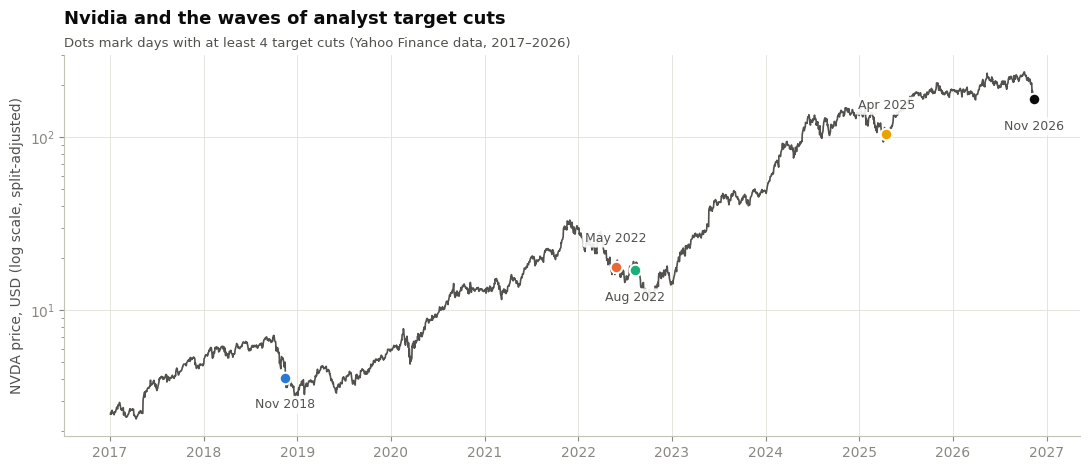

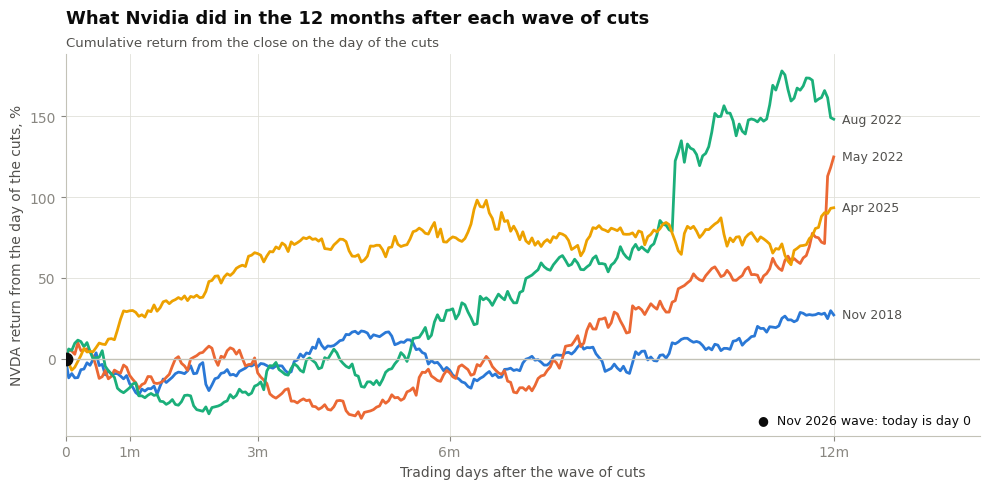

In [6]:
COLORI = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 10,
})

def titoli(ax, titolo, sottotitolo):
    ax.set_title(titolo, loc="left", fontsize=13, fontweight="bold", color=INK, pad=22)
    ax.text(0, 1.02, sottotitolo, transform=ax.transAxes, fontsize=9.5, color="#52514e")

# --- Grafico 1: prezzo (scala log) con le ondate di tagli ---
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(P.index, P.values, color="#52514e", linewidth=1.2)
ax.set_yscale("log")
for k, d in enumerate(episodi):
    colore = COLORI[k] if k < len(COLORI) else INK
    ax.scatter([d], [P.loc[d]], s=70, color=colore, edgecolor="white", linewidth=1.5, zorder=3)
    sopra = k % 2 == 1                      # etichette alternate sopra/sotto per non sovrapporsi
    ax.annotate(d.strftime("%b %Y"), (d, P.loc[d]), textcoords="offset points",
                xytext=(0, 18 if sopra else -22), ha="center", fontsize=9, color="#52514e",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.9))
ax.set_ylabel("NVDA price, USD (log scale, split-adjusted)")
titoli(ax, "Nvidia and the waves of analyst target cuts",
       "Dots mark days with at least 4 target cuts (Yahoo Finance data, 2017–2026)")
plt.tight_layout()
plt.show()

# --- Grafico 2: percorso del titolo nei 12 mesi dopo ogni ondata ---
fig, ax = plt.subplots(figsize=(10, 5))
for k, d in enumerate(episodi):
    i = date_borsa.get_loc(d)
    tratto = P.iloc[i: i + 253] / P.iloc[i] - 1
    if len(tratto) < 2:
        continue
    giorni = np.arange(len(tratto))
    ax.plot(giorni, tratto.values * 100, color=COLORI[k % len(COLORI)], linewidth=2)
    ax.annotate(d.strftime("%b %Y"), (giorni[-1], tratto.values[-1] * 100), textcoords="offset points",
                xytext=(6, 0), va="center", fontsize=9, color="#52514e")
ax.scatter([0], [0], s=80, color=INK, zorder=4)
ax.text(0.99, 0.03, "●  Nov 2026 wave: today is day 0", transform=ax.transAxes,
        ha="right", fontsize=9, color=INK)
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.set_xticks([0, 21, 63, 126, 252])
ax.set_xticklabels(["0", "1m", "3m", "6m", "12m"])
ax.set_xlim(0, 300)
ax.set_xlabel("Trading days after the wave of cuts")
ax.set_ylabel("NVDA return from the day of the cuts, %")
titoli(ax, "What Nvidia did in the 12 months after each wave of cuts",
       "Cumulative return from the close on the day of the cuts")
plt.tight_layout()
plt.show()

## 7. Findings and limitations

**Findings** (4 past waves of target cuts: Nov 2018, May 2022, Aug 2022, Apr 2025)

1. **Analysts cut after the fall, not before it.** In every episode the stock was already 30–49% below its 52-week high when the cuts arrived. Target cuts largely follow the price.
2. **In the short run, analysts were often right.** In three of four episodes (2018, May 2022, Aug 2022) the stock kept falling for 3 months and dropped a further 23–37% before bottoming. Only April 2025 rebounded immediately.
3. **Over 12 months, the cuts were too pessimistic.** Twelve months later Nvidia was up in all four cases (+27% to +148%) and ahead of the S&P 500. In three of four cases the price was above the cut targets, and even above the targets before the cut. The exception is 2018, when the price stayed 13% below the cut target: that time analysts had not cut enough.
4. **Recovery took between 2 and 15 months** to get back to the 52-week high.
5. **Drawdowns of more than 25%** (5 past episodes) fell a further 1–54% after crossing −25%, and all eventually made a new all-time high, in 41 to 338 trading days.

**Why November 2026 is different**
- **Scale:** 9 downgrades in a week, against at most 3 in any past wave; past waves were mostly target trims with Buy ratings kept. The average cut (−32%) is also the largest in the sample.
- **Nature of the shock:** past waves followed cyclical earnings problems (crypto and gaming inventory in 2018 and 2022) or an export ban (2025). This one combines a governance issue at the CEO level, regulatory and export-control risk, and a political shift after the midterm elections.
- **Fundamentals:** in 2018 and 2022, earnings were falling, which is when the stock kept dropping after the cuts. In 2025 fundamentals were intact and the rebound was the fastest. The Q3 FY2027 results (17 November 2026) will show which pattern is closer.

**Limitations**
- **Hindsight and survivorship bias:** Nvidia is one of the biggest winners in market history, so "it always recovered" is partly built into the sample. A fair test needs stocks where analysts were right (e.g., Intel).
- **Few episodes:** four cut waves and five drawdowns cannot give reliable probabilities.
- **Data:** Yahoo Finance covers fewer brokers before 2022 than I/B/E/S, and its timestamps are approximate.
- This is a historical description, not a forecast.